Here we try to train a shallow MLP to act as a toy score model.
We will start with a data distribution that has a known analytic form and should be easy for a linear regression to estimate.
We can then attempt to sample from the score model using annealed Langevin dynamics.

Observations:
- A shallow MLP with a ReLU activation falls apart when attempting to model with num_gaussians > 2
- Fitting also falls apart when attempting to model data with dims > 2
- Areas in the vector field where p_data(x) is close to zero tend to have the highest difference. That's not
  correct though, since the very low p_data(x) is artificially increasing the l2 norm.

Questions:
- See Claude chat: "Is it possible to estimate the probability of drawing a sample from a distribution? Or at least have some relative measure of likelyhood? Is there a way to use Langevin dynamics to retrieve specific samples from the distribution?"
  - See if we can implement answeres to those questions.
- What are the shortcomings of using score based models -> keep reading Yang's blog post.

In [161]:
import torch
import torch.nn as nn
import torch.distributions as dist
import matplotlib.pyplot as plt

# Create a mixture of K D-dimensional Gaussians
def create_mixed_gaussians(num_gaussians, dims):
    # Must be positive and sum to 1
    mix_weights = torch.randn(num_gaussians).abs()
    mix_weights = mix_weights / mix_weights.sum()
    mixtures = dist.Categorical(mix_weights)

    means  = torch.rand(num_gaussians, dims)
    stds = torch.rand(num_gaussians, dims)
    components = dist.Normal(means, stds)
    # Batch: num_gaussians, Events: dims
    components = dist.Independent(components, 1)
    return dist.MixtureSameFamily(mixtures, components)

def true_log_probs(gmm, x):
    samples = x.detach().clone().requires_grad_(True)
    (grad,) = torch.autograd.grad(gmm.log_prob(samples).sum(), samples)
    return grad

def fisher_loss(predicted, target):  # (N, D) input, scalar output
    return 0.5 * (predicted - target).square().sum(dim=-1).mean()

class ScoreModel(nn.Module):
    def __init__(self, dim, hidden_dim=128):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, dim),
        )

    def forward(self, x):
        return self.layers(x)

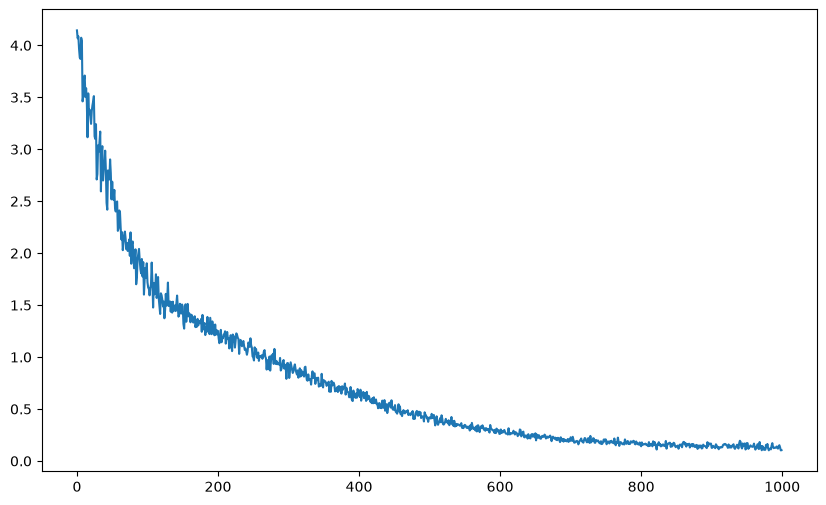

In [157]:

torch.manual_seed(67)
num_gaussians, dims = 2, 2
batch_size, epochs = 256, 1000
gmm = create_mixed_gaussians(num_gaussians, dims)

model = ScoreModel(dims)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
losses = []

for epoch in range(epochs):
    samples = gmm.sample((batch_size,)).requires_grad_(True)
    # NOTE: we don't need to get the log gradients of the score model -> the model should predict that directly
    target = true_log_probs(gmm, samples)
    predicted = model(samples)
    loss = fisher_loss(predicted, target)

    losses.append(loss.item())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    """
    if (epoch+1) % 100 == 0:
        # Smaller value = lighter cell!
        plt.title(f"Epoch {epoch+1} - true log probs")
        plt.axis("off")
        plt.figure(figsize=((10, 3)))
        plt.imshow(target.detach().clone().T, aspect="auto", cmap="gray_r")

        plt.title(f"Epoch {epoch+1} - vector field")
        plt.axis("off")
        plt.figure(figsize=((10, 3)))
        field = (predicted - target).square().detach().clone()
        plt.imshow(field.T, aspect="auto", cmap="gray_r")
    """

plt.figure(figsize=(10, 6))
plt.plot(torch.arange(epochs), losses)
torch.save(model.state_dict(), "model_weights.pth")

In [163]:
# langevin dynamics allows us to sample an unknown distribution near its
# densities. tepping in proportion to the density at a point should should
# steer us towards high density areas, especially in higher dimensions.
# Introducing noise gives us the freedom to explore the space. Annealing eps
# lets us step wildly at the beginning then hone in at the end, but of course
# there's always the possibility that we don't step broadly enough, or that we
# step too broadly, missing the high density regions.
def annealed_langevin(n_samples, steps, score_func, dims, eps0, beta, gamma):
    samples = torch.randn(n_samples, dims)
    for t in range(steps):
        eps = eps0 / (beta + t) ** gamma
        noise = torch.randn(n_samples, dims)
        samples = samples - 0.5 * eps * score_func(samples) + eps ** 0.5 * noise
    return samples


model = ScoreModel(dims)
model.load_state_dict(torch.load("model_weights.pth", weights_only=True))
samples = annealed_langevin(4, 100, model, dims, 1e-3, 500, 0.6)
samples

tensor([[ 0.1071,  0.1912],
        [ 0.3339, -0.1621],
        [-1.6182,  0.1060],
        [ 0.0789,  0.0138]], grad_fn=<AddBackward0>)